# Experiment 013: 7B SFT-to-GRPO seed-0 analysis plots

This notebook checks the completed 7B phase 1 run, plots training and evaluation,
and adds the preliminary 7B point to the A100 warm-route scale comparison.
Generative exact match stays primary and the letter probe stays diagnostic.

Phase 1 contains only seed 0. The registered 7B primary endpoint needs seed 1 in
phase 2, so every 7B scale statement here remains a single-seed extension.
Figures are saved to `analysis/figures/013_1/`.


In [15]:
# load the 013 result and the matched A100 scale runs
import json
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if not (ROOT / 'config.py').exists():
    raise FileNotFoundError('repository root containing config.py was not found')
sys.path.insert(0, str(ROOT))

from analysis.stats import align_pred_rows, holm, mcnemar_exact, paired_delta_ci
from data.subjects import TIERS as VALIDATED_TIERS
from eval.metrics import bootstrap_ci

RES = ROOT / 'results'
RUN13 = RES / '013_COLAB_FULL_B7_sft_grpo_seed0'
BASE13 = RES / 'base_evals' / '013_COLAB_FULL_B7'
FIG = ROOT / 'analysis' / 'figures' / '013_1'
FIG.mkdir(parents=True, exist_ok=True)

SCALE_RUNS = {
    '0.5B': {
        'params': 0.5, 'seeds': (0, 1, 2),
        'runs': {seed: RES / f'006_COLAB_FULL_B05_sft_grpo_seed{seed}' for seed in (0, 1, 2)},
        'base': RES / 'base_evals' / '006_COLAB_FULL_B05',
    },
    '1.5B': {
        'params': 1.5, 'seeds': (0, 1),
        'runs': {seed: RES / f'009_COLAB_FULL_B15_sft_grpo_seed{seed}' for seed in (0, 1)},
        'base': RES / 'base_evals' / '009_COLAB_FULL_B15',
    },
    '3B': {
        'params': 3.0, 'seeds': (0, 1),
        'runs': {seed: RES / f'003_COLAB_FULL_B3_sft_grpo_seed{seed}' for seed in (0, 1)},
        'base': RES / 'base_evals' / '003_COLAB_FULL_B3',
    },
    '7B': {
        'params': 7.0, 'seeds': (0,), 'runs': {0: RUN13}, 'base': BASE13,
    },
}

plt.style.use('seaborn-v0_8-whitegrid')
COLORS = {'base': '#4C78A8', 'sft': '#54A24B', 'grpo': '#F58518', 'probe': '#9D9DA1'}
TIER_COLORS = {'easy': '#59A14F', 'medium': '#F28E2B', 'hard': '#E15759', 'overall': '#4C4C4C'}
TIERS = ['easy', 'medium', 'hard']
GROUPS = TIERS + ['overall']
CONDITIONS = ['base', 'sft', 'grpo']
CONDITION_LABELS = {'base': 'base', 'sft': 'GSM8K SFT', 'grpo': 'SFT + GRPO'}
TIER_LOOKUP = {subject: tier for tier, subjects in VALIDATED_TIERS.items() for subject in subjects}
SUBJECTS = [subject for tier in TIERS for subject in VALIDATED_TIERS[tier]]
EXPECTED = {
    'sft_eval.json', 'sft_logprob.json', 'sft_preds.jsonl', 'sft_logprob_preds.jsonl',
    'sft_trainlog.json', 'grpo_eval.json', 'grpo_logprob.json', 'grpo_preds.jsonl',
    'grpo_logprob_preds.jsonl', 'grpo_trainlog.json', 'summary.json', 'manifest.json', 'run.log',
}

def jload(path):
    with open(path) as handle:
        return json.load(handle)

def jsonl(path):
    with open(path) as handle:
        rows = [json.loads(line) for line in handle if line.strip()]
    return [{**row, 'tier': TIER_LOOKUP[row['subject']]} for row in rows]

def raw_jsonl(path):
    with open(path) as handle:
        return [json.loads(line) for line in handle if line.strip()]

def series(trainlog, key):
    rows = [row for row in trainlog if key in row and 'step' in row]
    return np.asarray([row['step'] for row in rows]), np.asarray([row[key] for row in rows], dtype=float)

def smooth(values, window=20):
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode='valid')

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=300, bbox_inches='tight')
    print('saved', name)

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

def group_rows(rows, group):
    return rows if group == 'overall' else [row for row in rows if row['tier'] == group]

def group_accuracy(rows, group):
    return accuracy(group_rows(rows, group))

def group_ci(rows, group, seed):
    selected = group_rows(rows, group)
    return bootstrap_ci([row['pred'] for row in selected], [row['gold'] for row in selected], seed=seed)

def paired_correct(rows_a, rows_b, group='overall'):
    rows_a, rows_b = align_pred_rows(rows_a, rows_b)
    if group != 'overall':
        rows_a = [row for row in rows_a if row['tier'] == group]
        rows_b = [row for row in rows_b if row['tier'] == group]
    if len(rows_a) != len(rows_b):
        raise ValueError('paired prediction counts differ')
    return [bool(row['correct']) for row in rows_a], [bool(row['correct']) for row in rows_b]

def paired_stats(rows_a, rows_b, seed):
    output = []
    for index, group in enumerate(GROUPS):
        correct_a, correct_b = paired_correct(rows_a, rows_b, group)
        delta, lo, hi = paired_delta_ci(correct_a, correct_b, seed=seed + index)
        a_only = sum(a and not b for a, b in zip(correct_a, correct_b))
        b_only = sum((not a) and b for a, b in zip(correct_a, correct_b))
        output.append({
            'group': group, 'delta': delta, 'ci_lo': lo, 'ci_hi': hi,
            'sft_only_correct': a_only, 'grpo_only_correct': b_only,
            'mcnemar_p': mcnemar_exact(a_only, b_only),
        })
    adjusted = holm([row['mcnemar_p'] for row in output[:3]])
    for row, value in zip(output[:3], adjusted):
        row['holm_p_tiers'] = value
    output[-1]['holm_p_tiers'] = np.nan
    return output

def load_run(run_dir, base_dir):
    return {
        'g': jload(run_dir / 'grpo_trainlog.json'),
        's': jload(run_dir / 'sft_trainlog.json'),
        'eval': {c: jload((base_dir if c == 'base' else run_dir) / f'{c}_eval.json') for c in CONDITIONS},
        'lp': {c: jload((base_dir if c == 'base' else run_dir) / f'{c}_logprob.json') for c in CONDITIONS},
        'preds': {c: jsonl((base_dir if c == 'base' else run_dir) / f'{c}_preds.jsonl') for c in CONDITIONS},
        'lp_preds': {c: jsonl((base_dir if c == 'base' else run_dir) / f'{c}_logprob_preds.jsonl') for c in CONDITIONS},
        'man': jload(run_dir / 'manifest.json'),
        'summary': jload(run_dir / 'summary.json'),
        'log': (run_dir / 'run.log').read_text(),
    }

D13 = load_run(RUN13, BASE13)
SCALE_DATA = {
    scale: {seed: load_run(info['runs'][seed], info['base']) for seed in info['seeds']}
    for scale, info in SCALE_RUNS.items()
}
MISSING = sorted(name for name in EXPECTED if not (RUN13 / name).exists())

paired_correct(D13['preds']['sft'], D13['preds']['grpo'])
assert not MISSING
assert max(row['step'] for row in D13['s'] if 'step' in row) == 500
assert len([row for row in D13['g'] if 'reward' in row]) == 500
assert all(D13['eval'][condition]['n_items'] == 1884 for condition in CONDITIONS)
assert all(len(D13['preds'][condition]) == 1884 for condition in CONDITIONS)
assert D13['man']['model_id'] == 'Qwen/Qwen2.5-7B'
assert D13['man']['resolved_dtype'] == 'bfloat16'
assert 'A100-SXM4-80GB' in D13['man']['gpu']['device']
assert D13['man']['config']['exec']['allow_oom_fallback'] is False
assert D13['man']['git']['dirty'] is False
assert D13['log'].count('done. total wall time') == 1
assert not any(term in D13['log'].lower() for term in ['traceback', 'out of memory', 'protocol abort', 'keyboardinterrupt'])
for scale, runs in SCALE_DATA.items():
    for seed, data in runs.items():
        assert 'A100' in data['man']['gpu']['device']
        recorded_dtype = data['man'].get('resolved_dtype')
        assert recorded_dtype in (None, 'bfloat16')
        if recorded_dtype is None:
            assert scale == '3B' and seed == 0
        assert len(data['preds']['grpo']) == 1884

print('loaded and checked experiment 013 seed 0')
print('003 seed 0 predates the resolved_dtype manifest field; its run record identifies A100 BF16')
print('figures ->', FIG)


loaded and checked experiment 013 seed 0
003 seed 0 predates the resolved_dtype manifest field; its run record identifies A100 BF16
figures -> /Users/oleggastov/Desktop/University UK/0006_City n St Georges Universities/003_Projects/INM363-IndividualProject-Dissertation/001_Code/analysis/figures/013_1


## 1. Run health and completion

The checks use the registered process criteria. Test accuracy is not used to decide
whether the later phases run.


In [16]:
reward_rows = [row for row in D13['g'] if 'reward' in row and 'step' in row]

def edge_mean(key, first=True, count=50):
    selected = reward_rows[:count] if first else reward_rows[-count:]
    return float(np.mean([row[key] for row in selected]))

def nonfinite_paths(value, path='root'):
    found = []
    if isinstance(value, dict):
        for key, item in value.items():
            found.extend(nonfinite_paths(item, f'{path}/{key}'))
    elif isinstance(value, list):
        for index, item in enumerate(value):
            found.extend(nonfinite_paths(item, f'{path}/{index}'))
    elif isinstance(value, float) and not math.isfinite(value):
        found.append(path)
    return found

invalid_values = nonfinite_paths(D13['s']) + nonfinite_paths(D13['g'])
unit_rows = raw_jsonl(RES / 'colab_units.jsonl')
unit_records = [row for row in unit_rows if row.get('notebook') == '013_colab_7b_phase1']
assert len(unit_records) == 1
unit_record = unit_records[0]

first_20_projection = np.mean([row['step_time'] for row in reward_rows[:20]]) * 500 / 3600
actual_grpo_hours = D13['man']['timings_sec']['grpo_train'] / 3600
health_tbl = pd.DataFrame([
    {'check': 'SFT steps', 'value': max(row['step'] for row in D13['s'] if 'step' in row), 'status': 'pass'},
    {'check': 'GRPO reward steps', 'value': len(reward_rows), 'status': 'pass'},
    {'check': 'items per evaluation', 'value': D13['eval']['grpo']['n_items'], 'status': 'pass'},
    {'check': 'A1 first-50 clipped ratio', 'value': edge_mean('completions/clipped_ratio'), 'status': 'pass below 0.30'},
    {'check': 'A2 last-50 KL', 'value': edge_mean('kl', first=False), 'status': 'pass, policy moved'},
    {'check': 'A4 first-20 projection, h', 'value': first_20_projection, 'status': 'pass below 24 h'},
    {'check': 'actual GRPO training, h', 'value': actual_grpo_hours, 'status': 'complete'},
    {'check': 'non-finite values', 'value': len(invalid_values), 'status': 'pass'},
    {'check': 'peak VRAM, GB', 'value': D13['man']['gpu']['peak_vram_gb'], 'status': 'no OOM'},
    {'check': 'Colab units used', 'value': unit_record['colab_cu_used'], 'status': 'logged'},
]).set_index('check')
display(health_tbl.round(4))

window_specs = [
    ('rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
    ('rewards/format_reward/mean', 'full-format reward rate', 0.2),
    ('kl', 'KL', 1.0),
    ('frac_reward_zero_std', 'zero reward variation', 1.0),
    ('completions/mean_length', 'mean rollout length', 1.0),
    ('completions/clipped_ratio', 'clipped ratio', 1.0),
]
window_rows = []
for key, label, divisor in window_specs:
    first = edge_mean(key, first=True) / divisor
    last = edge_mean(key, first=False) / divisor
    window_rows.append({'metric': label, 'first 50': first, 'last 50': last, 'change': last - first})
window_tbl = pd.DataFrame(window_rows).set_index('metric')
display(window_tbl.round(4))


,value,status
check,,
SFT steps,500.0000,pass
GRPO reward steps,500.0000,pass
items per evaluation,1884.0000,pass
A1 first-50 clipped ratio,0.0150,pass below 0.30
A2 last-50 KL,0.0122,"pass, policy moved"
"A4 first-20 projection, h",2.9957,pass below 24 h
"actual GRPO training, h",2.9679,complete
non-finite values,0.0000,pass
"peak VRAM, GB",71.3170,no OOM


,first 50,last 50,change
metric,,,
accuracy reward,0.7025,0.6925,-0.0100
full-format reward rate,0.9000,0.9625,0.0625
KL,0.0009,0.0122,0.0113
zero reward variation,0.2400,0.5400,0.3000
mean rollout length,112.9025,89.8325,-23.0700
clipped ratio,0.0150,0.0175,0.0025


## 2. Training behaviour


saved fig01_training_rewards


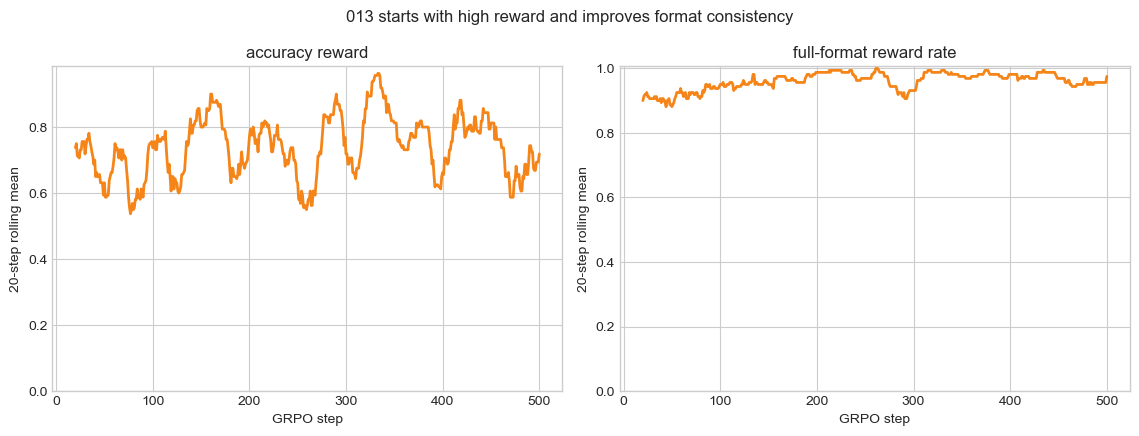

In [17]:
window = 20
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
for ax, key, title, divisor in [
    (axes[0], 'rewards/accuracy_reward/mean', 'accuracy reward', 1.0),
    (axes[1], 'rewards/format_reward/mean', 'full-format reward rate', 0.2),
]:
    x, values = series(D13['g'], key)
    ax.plot(x[window - 1:], smooth(values / divisor, window), color=COLORS['grpo'], lw=2)
    ax.set_title(title)
    ax.set_xlabel('GRPO step')
    ax.set_ylabel('20-step rolling mean')
    ax.set_ylim(bottom=0)
fig.suptitle('013 starts with high reward and improves format consistency')
fig.tight_layout()
save(fig, 'fig01_training_rewards')
plt.show()


saved fig02_optimisation_health


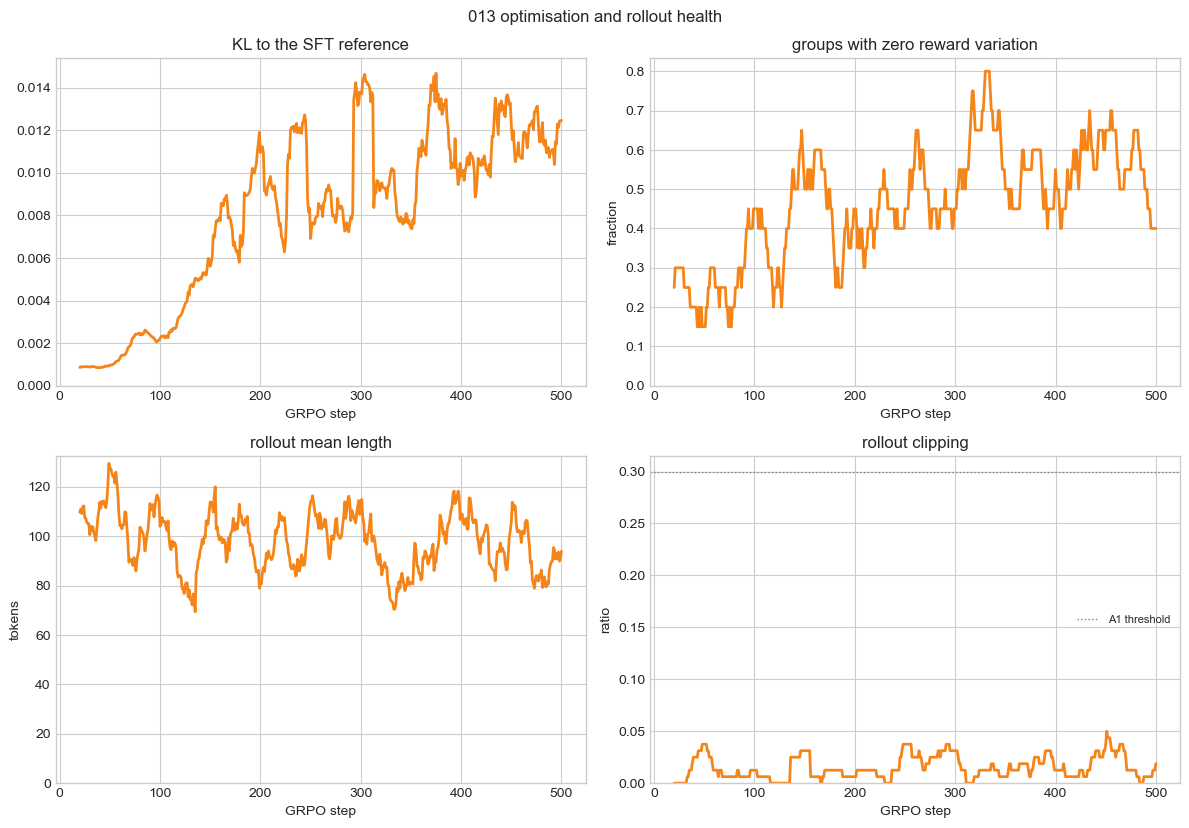

In [18]:
panels = [
    ('kl', 'KL to the SFT reference', None),
    ('frac_reward_zero_std', 'groups with zero reward variation', 'fraction'),
    ('completions/mean_length', 'rollout mean length', 'tokens'),
    ('completions/clipped_ratio', 'rollout clipping', 'ratio'),
]
fig, axes = plt.subplots(2, 2, figsize=(12, 8.4))
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    x, values = series(D13['g'], key)
    ax.plot(x[window - 1:], smooth(values, window), color=COLORS['grpo'], lw=2)
    if key == 'completions/clipped_ratio':
        ax.axhline(0.3, color='grey', ls=':', lw=1, label='A1 threshold')
        ax.legend(fontsize=8)
    ax.set_title(title)
    ax.set_xlabel('GRPO step')
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.set_ylim(bottom=0)
fig.suptitle('013 optimisation and rollout health')
fig.tight_layout()
save(fig, 'fig02_optimisation_health')
plt.show()


saved fig03_sft_loss


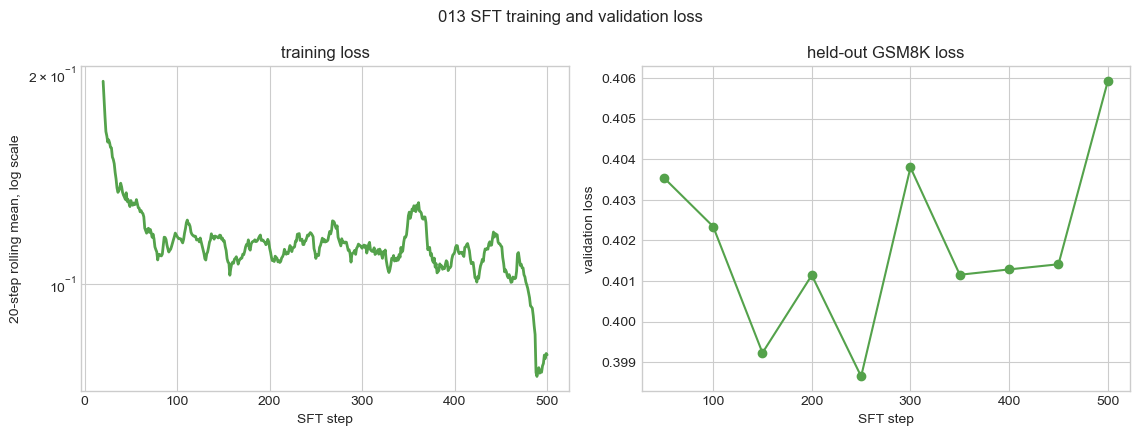

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
x, values = series(D13['s'], 'loss')
axes[0].plot(x[window - 1:], smooth(values, window), color=COLORS['sft'], lw=2)
axes[0].set_yscale('log')
axes[0].set_title('training loss')
axes[0].set_ylabel('20-step rolling mean, log scale')
x, values = series(D13['s'], 'eval_loss')
axes[1].plot(x, values, 'o-', color=COLORS['sft'], lw=1.5)
axes[1].set_title('held-out GSM8K loss')
axes[1].set_ylabel('validation loss')
for ax in axes:
    ax.set_xlabel('SFT step')
fig.suptitle('013 SFT training and validation loss')
fig.tight_layout()
save(fig, 'fig03_sft_loss')
plt.show()


## 3. Experiment 013 endpoint

These paired tests describe seed 0 only. Seed 1 is still needed for the main 7B result.


saved fig04_pipeline_accuracy


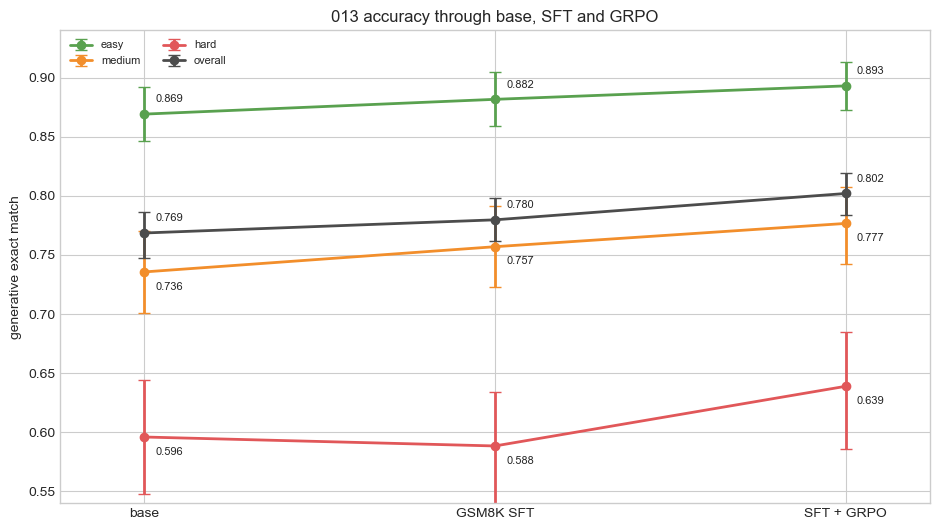

In [20]:
positions = np.arange(len(CONDITIONS))
fig, ax = plt.subplots(figsize=(9.5, 5.4))
for group_index, group in enumerate(GROUPS):
    values = [group_accuracy(D13['preds'][condition], group) for condition in CONDITIONS]
    cis = [group_ci(D13['preds'][condition], group, seed=1300 + group_index * 10 + index)
           for index, condition in enumerate(CONDITIONS)]
    errors = [[value - ci[0] for value, ci in zip(values, cis)],
              [ci[1] - value for value, ci in zip(values, cis)]]
    ax.errorbar(positions, values, yerr=errors, marker='o', lw=2, capsize=4,
                color=TIER_COLORS[group], label=group)
    for position, value in zip(positions, values):
        above = group in ('easy', 'overall')
        ax.annotate(f'{value:.3f}', (position, value), xytext=(8, 7 if above else -7),
                    textcoords='offset points', ha='left',
                    va='bottom' if above else 'top', fontsize=8)
ax.margins(x=0.12)
ax.set_xticks(positions)
ax.set_xticklabels([CONDITION_LABELS[condition] for condition in CONDITIONS])
ax.set_ylim(0.54, 0.94)
ax.set_ylabel('generative exact match')
ax.set_title('013 accuracy through base, SFT and GRPO')
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, 'fig04_pipeline_accuracy')
plt.show()


,delta,ci_lo,ci_hi,sft_only_correct,grpo_only_correct,mcnemar_p,holm_p_tiers
group,,,,,,,
easy,0.0114,-0.0046,0.0273,19,29,0.193413,0.222806
medium,0.0197,-0.0033,0.0411,18,30,0.111403,0.222806
hard,0.0505,0.0025,0.0985,38,58,0.051911,0.155732
overall,0.0223,0.0080,0.0366,75,117,0.002987,NaN


saved fig05_grpo_delta


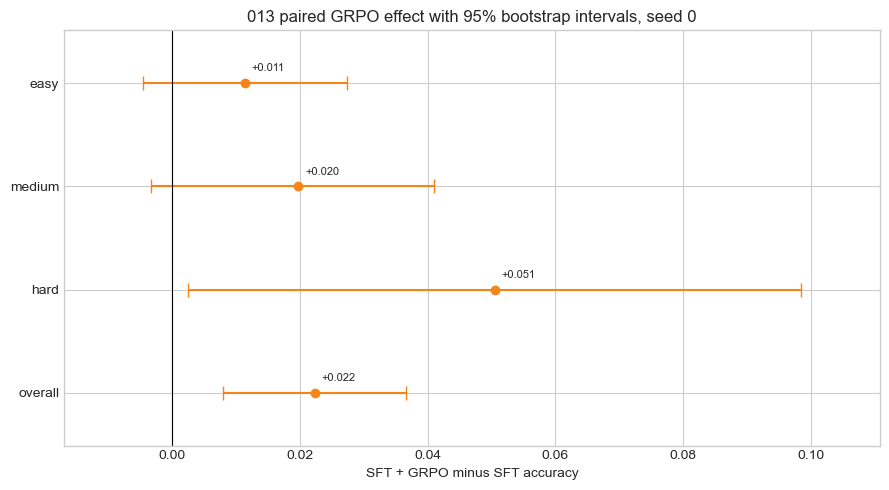

In [21]:
GRPO_STATS = paired_stats(D13['preds']['sft'], D13['preds']['grpo'], seed=1400)
grpo_stats_tbl = pd.DataFrame(GRPO_STATS).set_index('group').loc[GROUPS]
display(grpo_stats_tbl.round({'delta': 4, 'ci_lo': 4, 'ci_hi': 4, 'mcnemar_p': 8, 'holm_p_tiers': 8}))

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(GROUPS))
values = grpo_stats_tbl['delta'].to_numpy()
errors = [values - grpo_stats_tbl['ci_lo'].to_numpy(), grpo_stats_tbl['ci_hi'].to_numpy() - values]
ax.errorbar(values, y, xerr=errors, fmt='o', capsize=5, color=COLORS['grpo'])
ax.axvline(0, color='black', lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(GROUPS)
ax.invert_yaxis()
ax.set_xlabel('SFT + GRPO minus SFT accuracy')
ax.set_title('013 paired GRPO effect with 95% bootstrap intervals, seed 0')
ax.margins(x=0.12, y=0.17)
for position, value in zip(y, values):
    ax.annotate(f'{value:+.3f}', (value, position), xytext=(5 if value >= 0 else -5, 7),
                textcoords='offset points', ha='left' if value >= 0 else 'right',
                va='bottom', fontsize=8)
fig.tight_layout()
save(fig, 'fig05_grpo_delta')
plt.show()


## 4. What changed


saved fig06_generation_vs_probe


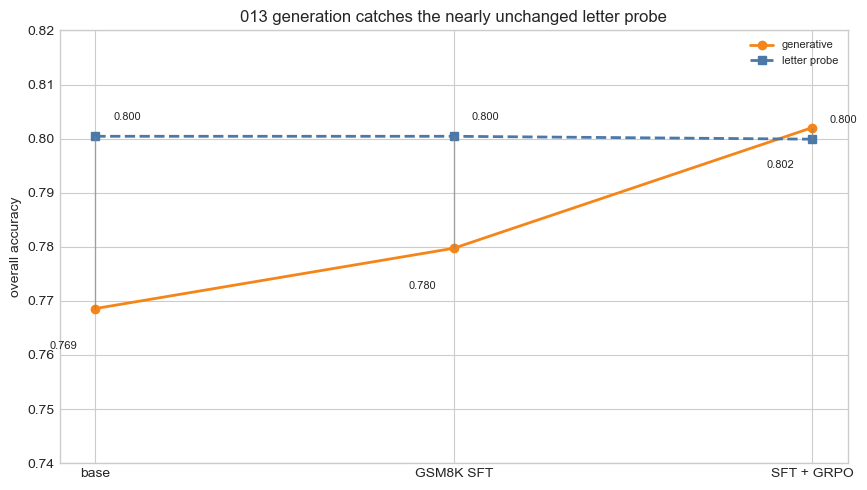

In [22]:
gen_values = [accuracy(D13['preds'][condition]) for condition in CONDITIONS]
probe_values = [accuracy(D13['lp_preds'][condition]) for condition in CONDITIONS]
fig, ax = plt.subplots(figsize=(8.8, 5))
ax.plot(positions, gen_values, 'o-', color=COLORS['grpo'], lw=2, label='generative')
ax.plot(positions, probe_values, 's--', color=COLORS['base'], lw=2, label='letter probe')
for position, gen_value, probe_value in zip(positions, gen_values, probe_values):
    ax.vlines(position, gen_value, probe_value, color='grey', lw=1, alpha=0.6)
    ax.text(position - 0.05, gen_value - 0.006, f'{gen_value:.3f}', ha='right', va='top', fontsize=8)
    ax.text(position + 0.05, probe_value + 0.003, f'{probe_value:.3f}', ha='left', fontsize=8)
ax.set_xticks(positions)
ax.set_xticklabels([CONDITION_LABELS[condition] for condition in CONDITIONS])
ax.set_ylim(0.74, 0.82)
ax.set_ylabel('overall accuracy')
ax.set_title('013 generation catches the nearly unchanged letter probe')
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, 'fig06_generation_vs_probe')
plt.show()


,format compliance,extraction failure,mean response length,correct and full format
condition,,,,
base,0.3493,0.0271,194.0748,0.2882
GSM8K SFT,0.9236,0.0223,87.2808,0.7357
SFT + GRPO,0.9841,0.0117,66.4512,0.7999


saved fig07_eval_diagnostics


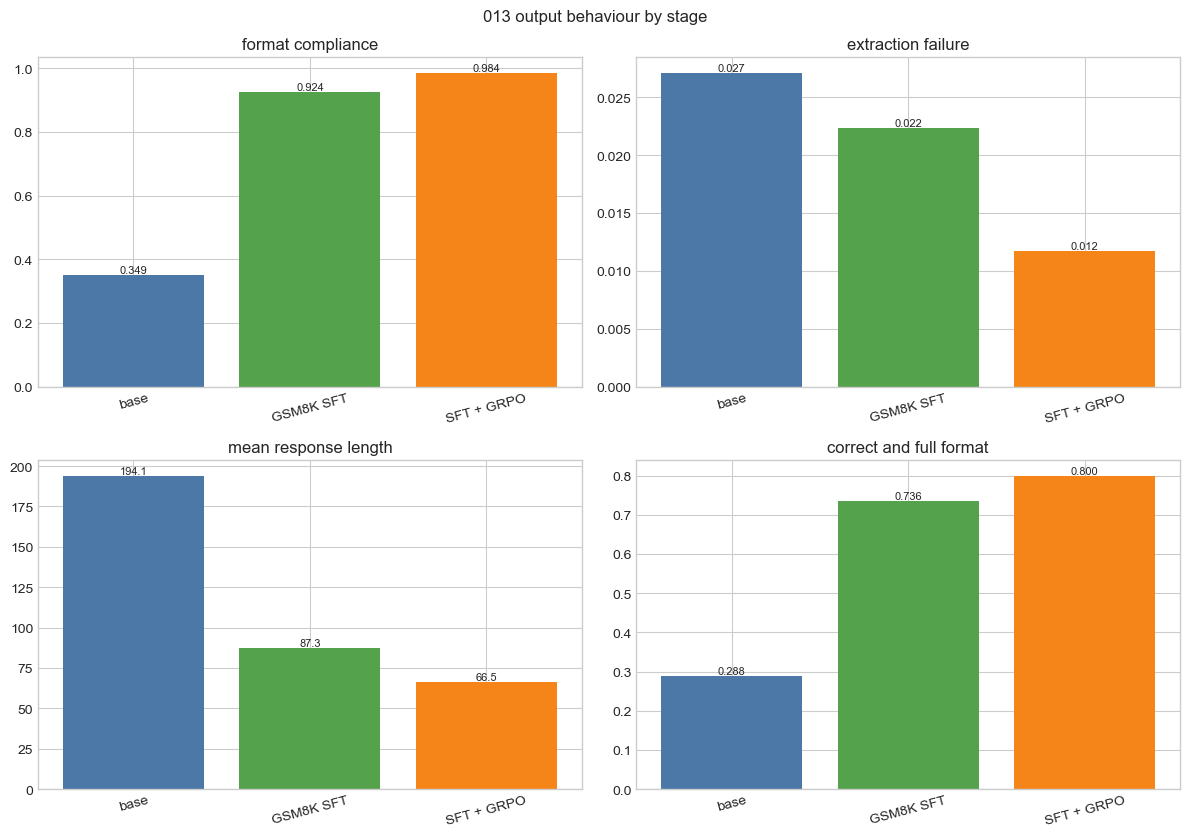

In [23]:
diagnostic_rows = []
for condition in CONDITIONS:
    predictions = D13['preds'][condition]
    diagnostic_rows.append({
        'condition': CONDITION_LABELS[condition],
        'format compliance': D13['eval'][condition]['format_compliance'],
        'extraction failure': D13['eval'][condition]['extraction_failure_rate'],
        'mean response length': D13['eval'][condition]['mean_len'],
        'correct and full format': np.mean([row['correct'] and row['format_ok'] for row in predictions]),
    })
diagnostics_tbl = pd.DataFrame(diagnostic_rows).set_index('condition')
display(diagnostics_tbl.round(4))

fig, axes = plt.subplots(2, 2, figsize=(12, 8.5))
metrics = ['format compliance', 'extraction failure', 'mean response length', 'correct and full format']
for ax, metric in zip(axes.flat, metrics):
    values = diagnostics_tbl[metric].to_numpy()
    bars = ax.bar(np.arange(len(CONDITIONS)), values, color=[COLORS[condition] for condition in CONDITIONS])
    for bar, value in zip(bars, values):
        label = f'{value:.1f}' if metric == 'mean response length' else f'{value:.3f}'
        ax.text(bar.get_x() + bar.get_width() / 2, value, label, ha='center', va='bottom', fontsize=8)
    ax.set_xticks(np.arange(len(CONDITIONS)))
    ax.set_xticklabels([CONDITION_LABELS[condition] for condition in CONDITIONS], rotation=15)
    ax.set_title(metric)
fig.suptitle('013 output behaviour by stage')
fig.tight_layout()
save(fig, 'fig07_eval_diagnostics')
plt.show()


saved fig08_subject_changes


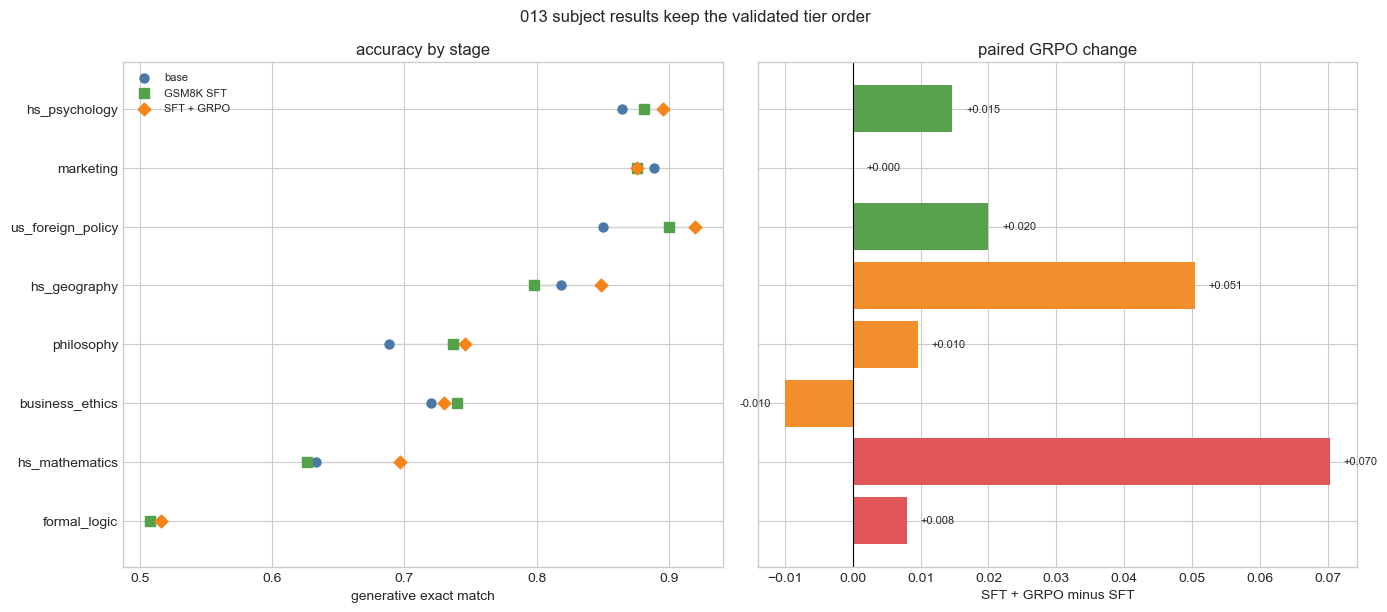

,tier,base,sft,grpo,delta
subject,,,,,
high_school_psychology,easy,0.8642,0.8807,0.8954,0.0147
marketing,easy,0.8889,0.8761,0.8761,0.0000
us_foreign_policy,easy,0.8500,0.9000,0.9200,0.0200
high_school_geography,medium,0.8182,0.7980,0.8485,0.0505
philosophy,medium,0.6881,0.7363,0.7460,0.0096
business_ethics,medium,0.7200,0.7400,0.7300,-0.0100
high_school_mathematics,hard,0.6333,0.6259,0.6963,0.0704
formal_logic,hard,0.5159,0.5079,0.5159,0.0079


In [24]:
subject_rows = []
for subject in SUBJECTS:
    row = {'subject': subject, 'tier': TIER_LOOKUP[subject]}
    for condition in CONDITIONS:
        row[condition] = D13['eval'][condition]['per_subject_acc'][subject]
    row['delta'] = row['grpo'] - row['sft']
    subject_rows.append(row)
subject_tbl = pd.DataFrame(subject_rows).set_index('subject')

labels = [subject.replace('high_school_', 'hs_') for subject in subject_tbl.index]
y = np.arange(len(subject_tbl))
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharey=True)
for position in y:
    axes[0].plot(subject_tbl.iloc[position][CONDITIONS], [position] * len(CONDITIONS), color='lightgrey', lw=1)
for condition, marker in zip(CONDITIONS, ['o', 's', 'D']):
    axes[0].scatter(subject_tbl[condition], y, color=COLORS[condition], marker=marker,
                    s=42, label=CONDITION_LABELS[condition], zorder=3)
axes[0].set_xlabel('generative exact match')
axes[0].set_title('accuracy by stage')
axes[0].legend(fontsize=8)
bars = axes[1].barh(y, subject_tbl['delta'], color=[TIER_COLORS[tier] for tier in subject_tbl['tier']])
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_xlabel('SFT + GRPO minus SFT')
axes[1].set_title('paired GRPO change')
for bar, value in zip(bars, subject_tbl['delta']):
    axes[1].text(value + (0.002 if value >= 0 else -0.002), bar.get_y() + bar.get_height() / 2,
                 f'{value:+.3f}', va='center', ha='left' if value >= 0 else 'right', fontsize=8)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels)
axes[0].invert_yaxis()
fig.suptitle('013 subject results keep the validated tier order')
fig.tight_layout()
save(fig, 'fig08_subject_changes')
plt.show()
display(subject_tbl.round(4))


## 5. Preliminary RQ2 scale extension

Experiments 006, 009, 003 and 013 use the same frozen SFT-to-GRPO route on A100
with BF16. The table keeps the 40GB and 80GB variants visible. No run used a
memory fallback. Seed counts are 3, 2, 2 and 1.


params_b                    GPU    base  base_probe     sft  \
scale seed                                                                
0.5B  0          0.5  NVIDIA A100-SXM4-40GB  0.1852      0.5669  0.2086   
      1          0.5  NVIDIA A100-SXM4-40GB  0.1852      0.5669  0.2389   
      2          0.5  NVIDIA A100-SXM4-40GB  0.1852      0.5669  0.2235   
1.5B  0          1.5  NVIDIA A100-SXM4-80GB  0.3710      0.6921  0.5478   
      1          1.5  NVIDIA A100-SXM4-80GB  0.3710      0.6921  0.5271   
3B    0          3.0  NVIDIA A100-SXM4-80GB  0.5934      0.7362  0.5340   
      1          3.0  NVIDIA A100-SXM4-80GB  0.5934      0.7362  0.5096   
7B    0          7.0  NVIDIA A100-SXM4-80GB  0.7686      0.8004  0.7797   

            sft_probe    grpo  grpo_probe  grpo_gain  
scale seed                                            
0.5B  0        0.5626  0.4623      0.5679     0.2537  
      1        0.5621  0.3153      0.5626     0.0764  
      2        0.5557  0.5058      0.5600     0.2824  
1.5B  0        0.6943  0.6741      0.7001     0.1263  
      1        0.6943  0.6348      0.6980     0.1077  
3B    0        0.7362  0.7160      0.7410     0.1821  
      1        0.7426  0.7266      0.7447     0.2171  
7B    0        0.8004  0.8020      0.7999     0.0223

,params_b,n_seeds,base_mean,base_min,base_max,sft_mean,sft_min,sft_max,grpo_mean,grpo_min,grpo_max,grpo_gain_mean,grpo_gain_min,grpo_gain_max,grpo_probe_mean,grpo_probe_min,grpo_probe_max,GPUs
scale,,,,,,,,,,,,,,,,,,
0.5B,0.5,3,0.1852,0.1852,0.1852,0.2236,0.2086,0.2389,0.4278,0.3153,0.5058,0.2042,0.0764,0.2824,0.5635,0.5600,0.5679,NVIDIA A100-SXM4-40GB
1.5B,1.5,2,0.3710,0.3710,0.3710,0.5374,0.5271,0.5478,0.6545,0.6348,0.6741,0.1170,0.1077,0.1263,0.6990,0.6980,0.7001,NVIDIA A100-SXM4-80GB
3B,3.0,2,0.5934,0.5934,0.5934,0.5218,0.5096,0.5340,0.7213,0.7160,0.7266,0.1996,0.1821,0.2171,0.7428,0.7410,0.7447,NVIDIA A100-SXM4-80GB
7B,7.0,1,0.7686,0.7686,0.7686,0.7797,0.7797,0.7797,0.8020,0.8020,0.8020,0.0223,0.0223,0.0223,0.7999,0.7999,0.7999,NVIDIA A100-SXM4-80GB


saved fig09_four_scale_curve


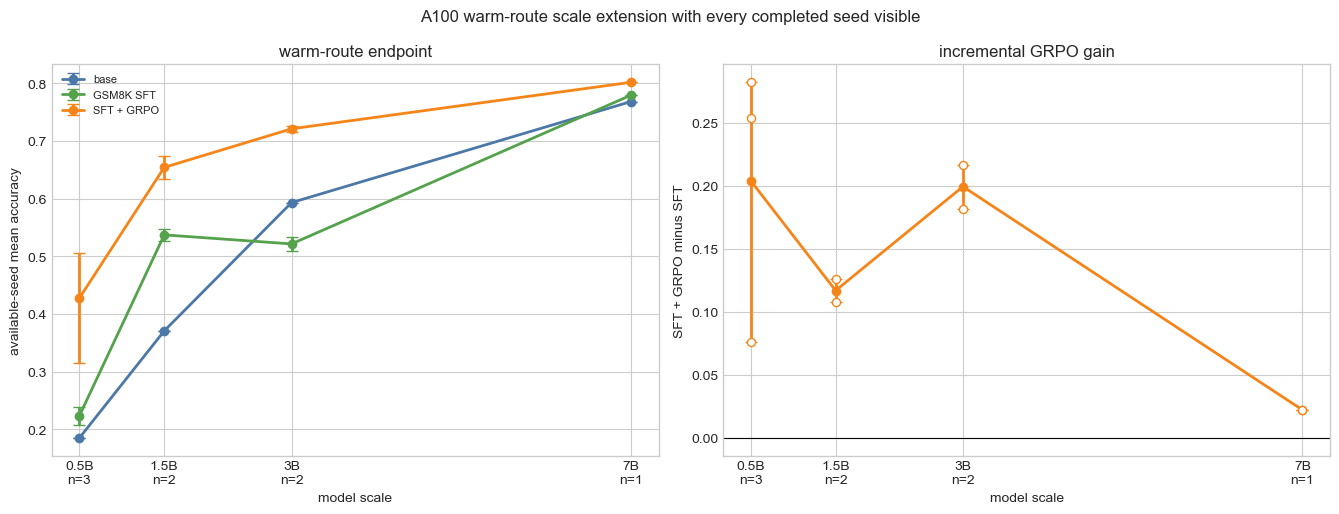

In [25]:
scale_rows = []
for scale, info in SCALE_RUNS.items():
    for seed in info['seeds']:
        data = SCALE_DATA[scale][seed]
        row = {'scale': scale, 'params_b': info['params'], 'seed': seed, 'GPU': data['man']['gpu']['device']}
        for condition in CONDITIONS:
            row[condition] = accuracy(data['preds'][condition])
            row[f'{condition}_probe'] = accuracy(data['lp_preds'][condition])
        row['grpo_gain'] = row['grpo'] - row['sft']
        scale_rows.append(row)
scale_seed_tbl = pd.DataFrame(scale_rows)

summary_rows = []
for (scale, params_b), group in scale_seed_tbl.groupby(['scale', 'params_b'], sort=False):
    row = {'scale': scale, 'params_b': params_b, 'n_seeds': len(group)}
    for key in ['base', 'sft', 'grpo', 'grpo_gain', 'grpo_probe']:
        row[f'{key}_mean'] = group[key].mean()
        row[f'{key}_min'] = group[key].min()
        row[f'{key}_max'] = group[key].max()
    row['GPUs'] = ', '.join(sorted(set(group['GPU'])))
    summary_rows.append(row)
scale_summary_tbl = pd.DataFrame(summary_rows).sort_values('params_b').set_index('scale')
display(scale_seed_tbl.set_index(['scale', 'seed']).round(4))
display(scale_summary_tbl.round(4))

x = scale_summary_tbl['params_b'].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for condition in CONDITIONS:
    values = scale_summary_tbl[f'{condition}_mean'].to_numpy()
    lower = values - scale_summary_tbl[f'{condition}_min'].to_numpy()
    upper = scale_summary_tbl[f'{condition}_max'].to_numpy() - values
    axes[0].errorbar(x, values, yerr=[lower, upper], marker='o', lw=2, capsize=4,
                     color=COLORS[condition], label=CONDITION_LABELS[condition])
axes[0].set_ylabel('available-seed mean accuracy')
axes[0].set_title('warm-route endpoint')
axes[0].legend(fontsize=8)

gain_means = scale_summary_tbl['grpo_gain_mean'].to_numpy()
gain_lo = gain_means - scale_summary_tbl['grpo_gain_min'].to_numpy()
gain_hi = scale_summary_tbl['grpo_gain_max'].to_numpy() - gain_means
axes[1].errorbar(x, gain_means, yerr=[gain_lo, gain_hi], marker='o', lw=2,
                 capsize=4, color=COLORS['grpo'], label='seed mean and range')
for scale, info in SCALE_RUNS.items():
    values = scale_seed_tbl.query('scale == @scale')['grpo_gain'].to_numpy()
    axes[1].scatter(np.repeat(info['params'], len(values)), values, s=34, facecolors='white',
                    edgecolors=COLORS['grpo'], zorder=3)
axes[1].axhline(0, color='black', lw=0.8)
axes[1].set_ylabel('SFT + GRPO minus SFT')
axes[1].set_title('incremental GRPO gain')
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels([f'{scale}\nn={int(scale_summary_tbl.loc[scale, "n_seeds"])}' for scale in scale_summary_tbl.index])
    ax.set_xlabel('model scale')
fig.suptitle('A100 warm-route scale extension with every completed seed visible')
fig.tight_layout()
save(fig, 'fig09_four_scale_curve')
plt.show()


saved fig10_scale_generation_vs_probe


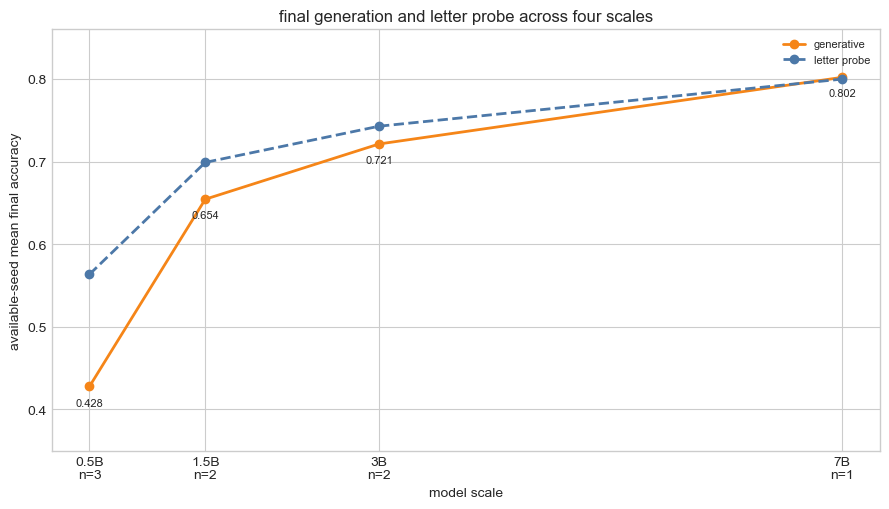

In [26]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for key, label, color, style in [
    ('grpo_mean', 'generative', COLORS['grpo'], '-'),
    ('grpo_probe_mean', 'letter probe', COLORS['base'], '--'),
]:
    values = scale_summary_tbl[key].to_numpy()
    ax.plot(x, values, marker='o', lw=2, ls=style, color=color, label=label)
for position, value, scale in zip(x, scale_summary_tbl['grpo_mean'], scale_summary_tbl.index):
    ax.annotate(f'{value:.3f}', (position, value), xytext=(0, -8),
                textcoords='offset points', ha='center', va='top', fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f'{scale}\nn={int(scale_summary_tbl.loc[scale, "n_seeds"])}' for scale in scale_summary_tbl.index])
ax.set_xlabel('model scale')
ax.set_ylabel('available-seed mean final accuracy')
ax.set_ylim(0.35, 0.86)
ax.set_title('final generation and letter probe across four scales')
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, 'fig10_scale_generation_vs_probe')
plt.show()


## 6. Compute and exact tables


,hours
base_eval,0.497
base_logprob_eval,0.009
sft_train,0.263
sft_eval,0.748
sft_logprob_eval,0.012
grpo_train,2.968
grpo_eval,0.521
grpo_logprob_eval,0.013
total,5.032


saved fig11_compute_timing


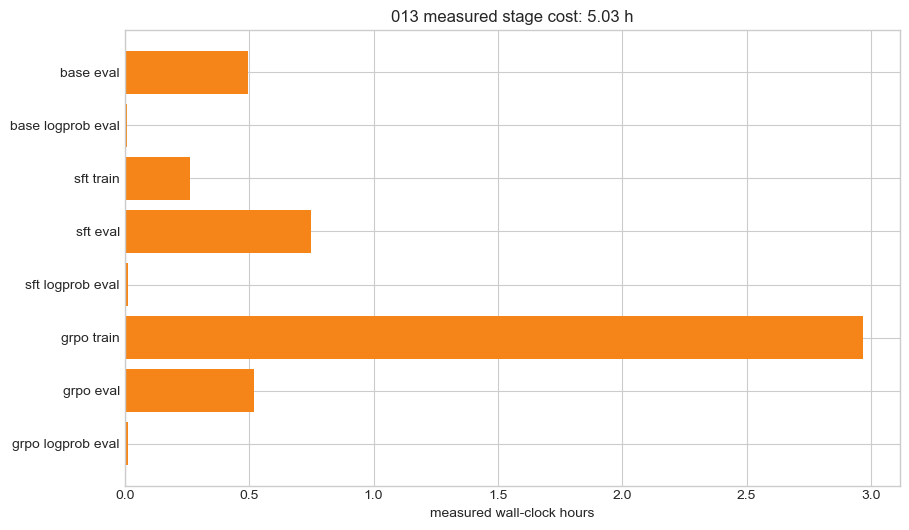

first-20 GRPO projection: 3.00 h
actual GRPO training: 2.97 h
compute units: 201.65 -> 168.69 = 32.96


In [27]:
stage_order = [
    'base_eval', 'base_logprob_eval', 'sft_train', 'sft_eval', 'sft_logprob_eval',
    'grpo_train', 'grpo_eval', 'grpo_logprob_eval',
]
compute_tbl = pd.DataFrame({
    'hours': [D13['man']['timings_sec'][stage] / 3600 for stage in stage_order]
}, index=stage_order)
compute_tbl.loc['total'] = compute_tbl.sum()
display(compute_tbl.round(3))

plot_tbl = compute_tbl.drop(index='total')
fig, ax = plt.subplots(figsize=(9.2, 5.4))
ax.barh(np.arange(len(plot_tbl)), plot_tbl['hours'], color=COLORS['grpo'])
ax.set_yticks(np.arange(len(plot_tbl)))
ax.set_yticklabels([label.replace('_', ' ') for label in plot_tbl.index])
ax.invert_yaxis()
ax.set_xlabel('measured wall-clock hours')
ax.set_title(f"013 measured stage cost: {compute_tbl.loc['total', 'hours']:.2f} h")
fig.tight_layout()
save(fig, 'fig11_compute_timing')
plt.show()
print(f"first-20 GRPO projection: {first_20_projection:.2f} h")
print(f"actual GRPO training: {actual_grpo_hours:.2f} h")
print(f"compute units: {unit_record['colab_cu_before']:.2f} -> {unit_record['colab_cu_after']:.2f} = {unit_record['colab_cu_used']:.2f}")


In [28]:
# keep the exact values used by the figures in compact tables
accuracy_rows = []
for condition in CONDITIONS:
    row = {'condition': CONDITION_LABELS[condition]}
    for group in GROUPS:
        row[f'gen_{group}'] = group_accuracy(D13['preds'][condition], group)
        row[f'probe_{group}'] = group_accuracy(D13['lp_preds'][condition], group)
    accuracy_rows.append(row)
accuracy_tbl = pd.DataFrame(accuracy_rows).set_index('condition')
display(accuracy_tbl.round(4))
display(grpo_stats_tbl.round(6))
display(subject_tbl.round(4))
display(scale_summary_tbl.round(4))
display(pd.DataFrame([unit_record]).set_index('session_id'))


,gen_easy,probe_easy,gen_medium,probe_medium,gen_hard,probe_hard,gen_overall,probe_overall
condition,,,,,,,,
base,0.8692,0.8976,0.7356,0.8128,0.5960,0.5657,0.7686,0.8004
GSM8K SFT,0.8817,0.8999,0.7570,0.8079,0.5884,0.5682,0.7797,0.8004
SFT + GRPO,0.8931,0.9022,0.7767,0.8079,0.6389,0.5606,0.8020,0.7999


,delta,ci_lo,ci_hi,sft_only_correct,grpo_only_correct,mcnemar_p,holm_p_tiers
group,,,,,,,
easy,0.011377,-0.004551,0.027304,19,29,0.193413,0.222806
medium,0.019704,-0.003284,0.041051,18,30,0.111403,0.222806
hard,0.050505,0.002525,0.098485,38,58,0.051911,0.155732
overall,0.022293,0.007962,0.036624,75,117,0.002987,NaN


,tier,base,sft,grpo,delta
subject,,,,,
high_school_psychology,easy,0.8642,0.8807,0.8954,0.0147
marketing,easy,0.8889,0.8761,0.8761,0.0000
us_foreign_policy,easy,0.8500,0.9000,0.9200,0.0200
high_school_geography,medium,0.8182,0.7980,0.8485,0.0505
philosophy,medium,0.6881,0.7363,0.7460,0.0096
business_ethics,medium,0.7200,0.7400,0.7300,-0.0100
high_school_mathematics,hard,0.6333,0.6259,0.6963,0.0704
formal_logic,hard,0.5159,0.5079,0.5159,0.0079


,params_b,n_seeds,base_mean,base_min,base_max,sft_mean,sft_min,sft_max,grpo_mean,grpo_min,grpo_max,grpo_gain_mean,grpo_gain_min,grpo_gain_max,grpo_probe_mean,grpo_probe_min,grpo_probe_max,GPUs
scale,,,,,,,,,,,,,,,,,,
0.5B,0.5,3,0.1852,0.1852,0.1852,0.2236,0.2086,0.2389,0.4278,0.3153,0.5058,0.2042,0.0764,0.2824,0.5635,0.5600,0.5679,NVIDIA A100-SXM4-40GB
1.5B,1.5,2,0.3710,0.3710,0.3710,0.5374,0.5271,0.5478,0.6545,0.6348,0.6741,0.1170,0.1077,0.1263,0.6990,0.6980,0.7001,NVIDIA A100-SXM4-80GB
3B,3.0,2,0.5934,0.5934,0.5934,0.5218,0.5096,0.5340,0.7213,0.7160,0.7266,0.1996,0.1821,0.2171,0.7428,0.7410,0.7447,NVIDIA A100-SXM4-80GB
7B,7.0,1,0.7686,0.7686,0.7686,0.7797,0.7797,0.7797,0.8020,0.8020,0.8020,0.0223,0.0223,0.0223,0.7999,0.7999,0.7999,NVIDIA A100-SXM4-80GB


,ts_start,notebook,colab_cu_before,unit_rate,ts_end,colab_cu_after,colab_cu_used,closed_on_resume
session_id,,,,,,,,
20260722_145839,2026-07-22 15:05,013_colab_7b_phase1,201.65,6.77,2026-07-22 20:12,168.69,32.96,False


## Cross-referenced conclusion

013 seed 0 finished normally on the A100 80GB in BF16. SFT and GRPO reached 500
steps and all evaluations have 1,884 items. Peak VRAM was 71.3 GB and there was no
OOM. Early clipping was 1.5%. The first-20 projection was 3.00 hours and the actual
GRPO time was 2.97 hours. Reward started high and stayed roughly flat, while KL
increased. Zero-variance groups averaged 54% in the last 50 steps. This looks more
like saturation than a failed run. GSM8K validation loss stayed close to 0.40 and
rose slightly at the end. It was used for monitoring only.

Generative accuracy moved from 76.86% at base to 77.97% after GSM8K SFT and 80.20%
after GRPO. The paired GRPO change is +2.23 points, with a 95% interval of +0.80 to
+3.66 points and McNemar p = .003. The easy, medium and hard changes are +1.14,
+1.97 and +5.05 points. No tier survives Holm correction. Six subjects improve,
marketing is unchanged and business ethics falls by one point. It's still one
trained seed, so it is not enough for a procedure-level 7B claim.

The letter probe stays around 80% through all stages. Format compliance moves from
34.9% to 92.4% to 98.4%, response length falls from 194 to 87 to 66 tokens, and
extraction failures fall to 1.2%. This again looks mainly like better elicitation and
output control. GRPO still adds accuracy after the format-competent SFT stage, so the
change is not only formatting.

The available-seed final GRPO means are 42.8%, 65.4%, 72.1% and 80.2% from 0.5B to
7B. The extra GRPO gains are 20.4, 11.7, 20.0 and 2.2 points, so the gain does not
follow a smooth scale curve. Seed counts are 3, 2, 2 and 1. The 7B point is still
preliminary until seed 1 is complete.

Tech health checks passed. Total time was 5.03 hours and the closed
record shows 32.96 compute units used.
